In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv


In [2]:
# Step 1: Import Required Libraries

# Import libraries for numerical operations and data handling
import numpy as np
import pandas as pd

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting and preprocessing data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer

# Import evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [3]:
# Step 2: Load the Energy Efficiency Dataset

# Read the dataset from Kaggle
df = pd.read_csv(
    '/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv'
)

# Display the first five rows
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
# Step 3: Separate Features and Target

# Select input features by removing both target columns
X = df.drop(columns=['Y1', 'Y2'])

# Select Heating Load as the target variable
y = df['Y1']

# Display the shapes of features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [5]:
# Step 4: Split the Dataset into Training and Testing Sets

# Split the data using the same settings as previous notebooks
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes of the resulting datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


In [6]:
# Step 5: Preprocess the Features

# Define categorical and numerical features
categorical_features = ['X6', 'X8']
numerical_features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

# Create a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit the preprocessor on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Display the processed data shapes
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (614, 16)
Testing shape: (154, 16)


In [7]:
# Step 6: Generate Polynomial Features

# Create a PolynomialFeatures transformer with degree 2
poly = PolynomialFeatures(degree=2, include_bias=False)

# Fit the transformer on training data and generate polynomial features
X_train_poly = poly.fit_transform(X_train_processed)

# Transform testing data using the same transformer
X_test_poly = poly.transform(X_test_processed)

# Display the shapes of the polynomial datasets
print("Training shape:", X_train_poly.shape)
print("Testing shape:", X_test_poly.shape)

Training shape: (614, 152)
Testing shape: (154, 152)


In [8]:
# Step 7: Scale the Target Variable (Heating Load)

# Create a StandardScaler for the target variable
y_scaler = StandardScaler()

# Fit the scaler on training target data and transform it
y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Transform testing target data using the same scaler
y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

# Display the shapes of the scaled target data
print("y_train_scaled shape:", y_train_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

y_train_scaled shape: (614,)
y_test_scaled shape: (154,)


In [9]:
# Step 8: Initialize RMSProp Optimizer

# Get the number of training samples and features
n_samples, n_features = X_train_poly.shape

# Initialize weights and bias with zeros
weights = np.zeros(n_features)
bias = 0.0

# Set the hyperparameters
learning_rate = 0.001
epochs = 100
beta = 0.9
epsilon = 1e-8

# Initialize squared gradient averages
squared_grad_w = np.zeros(n_features)
squared_grad_b = 0.0

# Store the training loss for each epoch
loss_history = []

In [10]:
# Step 9: Train the RMSProp Model

# Loop through the training epochs
for epoch in range(epochs):

    # Calculate predictions using current weights and bias
    y_pred = np.dot(X_train_poly, weights) + bias

    # Calculate prediction errors
    error = y_pred - y_train_scaled

    # Calculate gradients
    dw = (2 / n_samples) * np.dot(X_train_poly.T, error)
    db = (2 / n_samples) * np.sum(error)

    # Update the squared gradient averages
    squared_grad_w = beta * squared_grad_w + (1 - beta) * (dw ** 2)
    squared_grad_b = beta * squared_grad_b + (1 - beta) * (db ** 2)

    # Update weights using RMSProp
    weights -= learning_rate * dw / (np.sqrt(squared_grad_w) + epsilon)

    # Update bias using RMSProp
    bias -= learning_rate * db / (np.sqrt(squared_grad_b) + epsilon)

    # Calculate the training loss after updating parameters
    y_train_pred = np.dot(X_train_poly, weights) + bias
    loss = np.mean((y_train_pred - y_train_scaled) ** 2)

    # Store the loss
    loss_history.append(loss)

# Display the final training loss
print("Final Training Loss:", loss_history[-1])

Final Training Loss: 0.07230045871069501


In [11]:
# Step 10: Evaluate the RMSProp Model

# Make predictions on the test data
y_pred_scaled = np.dot(X_test_poly, weights) + bias

# Convert predictions back to the original target scale
y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Get the actual target values
y_test_original = y_test.to_numpy()

# Calculate evaluation metrics
mse = mean_squared_error(y_test_original, y_pred)
mae = mean_absolute_error(y_test_original, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred)

# Display the evaluation results
print("RMSProp Model Results:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

RMSProp Model Results:
MAE: 1.996482629898876
MSE: 8.938330432200562
RMSE: 2.989704071007792
R2 Score: 0.9142454424483494


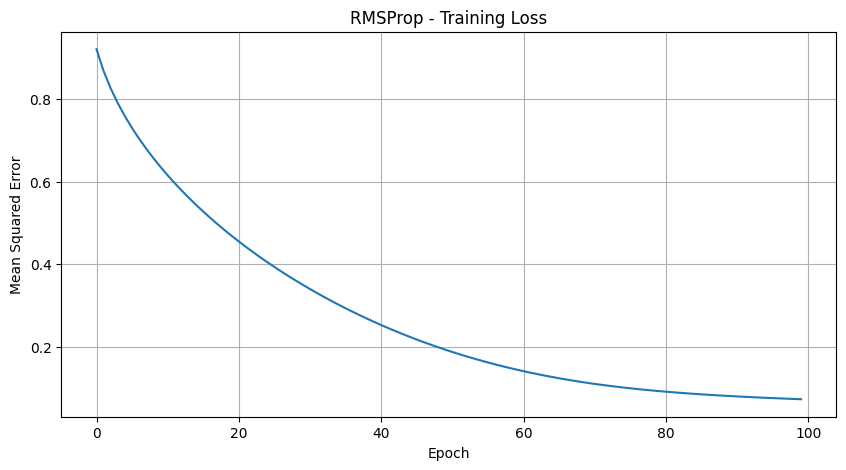

In [12]:
# Step 11: Plot RMSProp Training Loss

# Create a figure for the loss curve
plt.figure(figsize=(10, 5))

# Plot the training loss across epochs
plt.plot(loss_history)

# Add chart title and axis labels
plt.title("RMSProp - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

# Display the grid and plot
plt.grid(True)
plt.show()

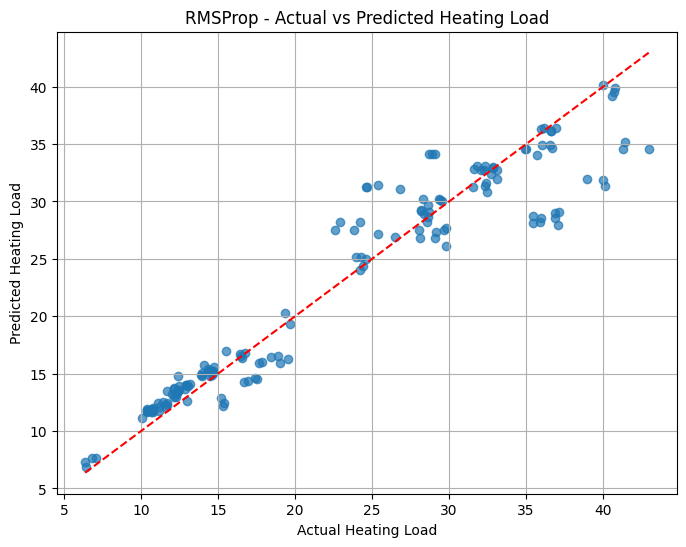

In [13]:
# Step 12: Plot Actual vs Predicted Values

# Create a figure for the comparison
plt.figure(figsize=(8, 6))

# Plot actual values against predicted values
plt.scatter(y_test_original, y_pred, alpha=0.7)

# Draw the ideal prediction line
plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

# Add chart title and axis labels
plt.title("RMSProp - Actual vs Predicted Heating Load")
plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")

# Display the grid and plot
plt.grid(True)
plt.show()